# Eksplorasi Data & Tahapan Preprocessing Segmentasi Parasit Malaria

Urutan notebook ini sengaja dibuat bertahap:

1. **Data per stadium, dipisah** (Bagian 2): tiap stadium ditampilkan sendiri, 4 crop *P. falciparum* + 4 crop *P. vivax*, lengkap dengan histogram intensitas stadium itu;
2. **Gabungan 32 citra** (Bagian 3): grid semua crop dan distribusi gabungan, seperti sebelumnya;
3. **Preprocessing** (Bagian 4–5): tahapan Lab b, koreksi background, median, CLAHE, Reinhard beserta histogram per tahap;
4. **Evaluasi segmentasi** (Bagian 6): Dice dihitung dan dibaca **per stadium** dulu, baru digabung untuk seluruh 32 citra.

Catatan istilah: malaria disebabkan **parasit** (*Plasmodium*), bukan virus. Dua dimensi label: **spesies** (*P. falciparum* / *P. vivax*) dan **stadium** (ring → trophozoite → schizont → gametocyte).

In [1]:
from pathlib import Path
import json, base64, zlib, io, warnings

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from skimage.filters import threshold_multiotsu
from skimage.morphology import remove_small_objects, disk

warnings.filterwarnings('ignore')
%matplotlib inline
cv2.setRNGSeed(42)
plt.rcParams['figure.dpi'] = 110

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'mp-idb-DatasetNinja').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == Path('/'):
        raise FileNotFoundError('Root proyek tidak ditemukan')

CROPS_DIR = PROJECT_ROOT / 'malaria_images'
ANN_DIR = PROJECT_ROOT / 'mp-idb-DatasetNinja' / 'ds' / 'ann'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'data_preprocessing'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PAD = 80
MIN_AREA = 12

STAGES = ['ring stage', 'trophozoite stage', 'schizont stage', 'gametocyte stage']
SPECIES = ['falciparum', 'vivax']
SHORT = {'falciparum': 'Pf', 'vivax': 'Pv'}
print('Crops:', CROPS_DIR, '|', len(list(CROPS_DIR.glob('*.png'))), 'file')

Crops: /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/malaria_images | 32 file


## 1. Muat crop + metadata + mask ground truth

In [2]:
meta = pd.read_csv(CROPS_DIR / 'metadata.csv')
display(meta)

_mask_cache = {}
def load_gt_mask(source_image, bbox):
    if source_image not in _mask_cache:
        ann = json.load(open(ANN_DIR / (source_image + '.json')))
        full = np.zeros((ann['size']['height'], ann['size']['width']), dtype=np.uint8)
        for obj in ann['objects']:
            origin = obj['bitmap']['origin']
            png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
            bm_arr = np.array(Image.open(io.BytesIO(png)))
            bm = (bm_arr[..., -1] if bm_arr.ndim == 3 else bm_arr) > 0
            h, w = bm.shape
            full[origin[1]:origin[1]+h, origin[0]:origin[0]+w] |= bm.astype(np.uint8)
        _mask_cache[source_image] = full
    x, y, w, h = int(bbox.bbox_x), int(bbox.bbox_y), int(bbox.bbox_w), int(bbox.bbox_h)
    return _mask_cache[source_image][max(0,y-PAD):y+h+PAD, max(0,x-PAD):x+w+PAD].astype(bool)

crops, gts = [], []
for _, r in meta.iterrows():
    img = cv2.cvtColor(cv2.imread(str(CROPS_DIR / r.filename), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    crops.append(img); gts.append(load_gt_mask(r.source_image, r))
print(f'{len(crops)} crop + mask GT dimuat')

print('\nJumlah crop per stadium x spesies:')
display(meta.pivot_table(index='stage', columns='species', values='filename',
                         aggfunc='count').reindex(STAGES))

,filename,species,stage,source_image,parasite_area_px,bbox_x,bbox_y,bbox_w,bbox_h,crop_size
0,falciparum_ring_1.png,falciparum,ring stage,1408161544-0001-S_R.jpg,22930,1009,578,187,163,347x323
1,falciparum_ring_2.png,falciparum,ring stage,1305121398-0019-R.jpg,20406,1088,969,164,154,324x314
2,falciparum_ring_3.png,falciparum,ring stage,1408161544-0002-R_S.jpg,18669,1218,640,160,156,320x316
3,falciparum_ring_4.png,falciparum,ring stage,1408161544-0003-R_S.jpg,16979,1030,677,148,146,308x306
4,falciparum_trophozoite_1.png,falciparum,trophozoite stage,1701151546-0015-R_T.jpg,12473,356,326,145,120,305x280
5,falciparum_trophozoite_2.png,falciparum,trophozoite stage,1603223711-0002-T_G.jpg,11425,1343,1010,192,107,352x267
6,falciparum_trophozoite_3.png,falciparum,trophozoite stage,1704282807-0021-T_G_R.jpg,11169,1220,732,82,194,242x354
7,falciparum_trophozoite_4.png,falciparum,trophozoite stage,1704282807-0013-R_T.jpg,9049,1314,761,112,104,272x264
8,falciparum_schizont_1.png,falciparum,schizont stage,1408161544-0001-S_R.jpg,22930,1009,578,187,163,347x323
9,falciparum_schizont_2.png,falciparum,schizont stage,1408161544-0002-R_S.jpg,18669,1218,640,160,156,320x316


32 crop + mask GT dimuat

Jumlah crop per stadium x spesies:


species,falciparum,vivax
stage,,
ring stage,4,4
trophozoite stage,4,4
schizont stage,4,4
gametocyte stage,4,4


## 2. Data per stadium (dipisah)

Sebelum digabung, tiap stadium dibaca sendiri-sendiri: 4 crop *P. falciparum* (baris atas, label `Pf`) dan 4 crop *P. vivax* (baris kedua, label `Pv`), ditambah **histogram intensitas grayscale** untuk stadium itu.

Pada histogram, tiap garis tipis = satu crop, area abu-abu = gabungan 4 crop spesies tersebut, garis putus-putus = rata-rata intensitas. Dengan cara ini pergeseran profil pewarnaan antar stadium terlihat tanpa tertutup stadium lain.

In [3]:
def gray_stack(idxs, size=256):
    return np.stack([cv2.resize(cv2.cvtColor(crops[i], cv2.COLOR_RGB2GRAY), (size, size)).ravel()
                     for i in idxs])

def plot_stage(st, bins=40):
    rows = meta[meta.stage == st]
    fig = plt.figure(figsize=(13.5, 6.4))
    gs = fig.add_gridspec(3, 4, height_ratios=[1.5, 1.5, 1.55], hspace=0.45, wspace=0.14)

    for i, sp in enumerate(SPECIES):
        idxs = meta.index[(meta.stage == st) & (meta.species == sp)].tolist()
        for k, idx in enumerate(idxs):
            ax = fig.add_subplot(gs[i, k])
            ax.imshow(crops[idx]); ax.axis('off')
            ax.set_title(f'{SHORT[sp]} {k+1} · {meta.parasite_area_px[idx]/1000:.0f}k px', fontsize=7)

    for i, sp in enumerate(SPECIES):
        ax = fig.add_subplot(gs[2, i * 2:(i + 1) * 2])
        idxs = meta.index[(meta.stage == st) & (meta.species == sp)].tolist()
        stack = gray_stack(idxs)
        for k, row in enumerate(stack):
            ax.hist(row, bins=bins, histtype='step', density=True, lw=1, alpha=0.75,
                    label=f'{SHORT[sp]} {k+1}')
        pooled = stack.mean(axis=0)
        ax.hist(pooled, bins=bins, density=True, color='slategray', alpha=0.35)
        ax.axvline(pooled.mean(), color='black', ls='--', lw=1,
                   label=f'rata2 {pooled.mean():.0f}')
        ax.set_title(f'Histogram intensitas — {sp}', fontsize=8)
        ax.set_xlabel('intensitas grayscale'); ax.set_yticks([])
        ax.legend(fontsize=6, ncol=2, loc='upper right', frameon=False)

    fig.suptitle(f'Stadium: {st} — {len(rows)} crop, luas parasit rata2 '
                 f'{rows.parasite_area_px.mean()/1000:.1f}k px '
                 f'(min {rows.parasite_area_px.min()/1000:.1f}k, max {rows.parasite_area_px.max()/1000:.1f}k)',
                 fontsize=11, y=0.99)
    plt.show()

plot_stage.__doc__ = 'Tampilkan 8 crop + histogram intensitas untuk satu stadium.'
print('Fungsi plot_stage siap dipakai untuk 4 stadium.')

Fungsi plot_stage siap dipakai untuk 4 stadium.


### 2.1 Stadium ring

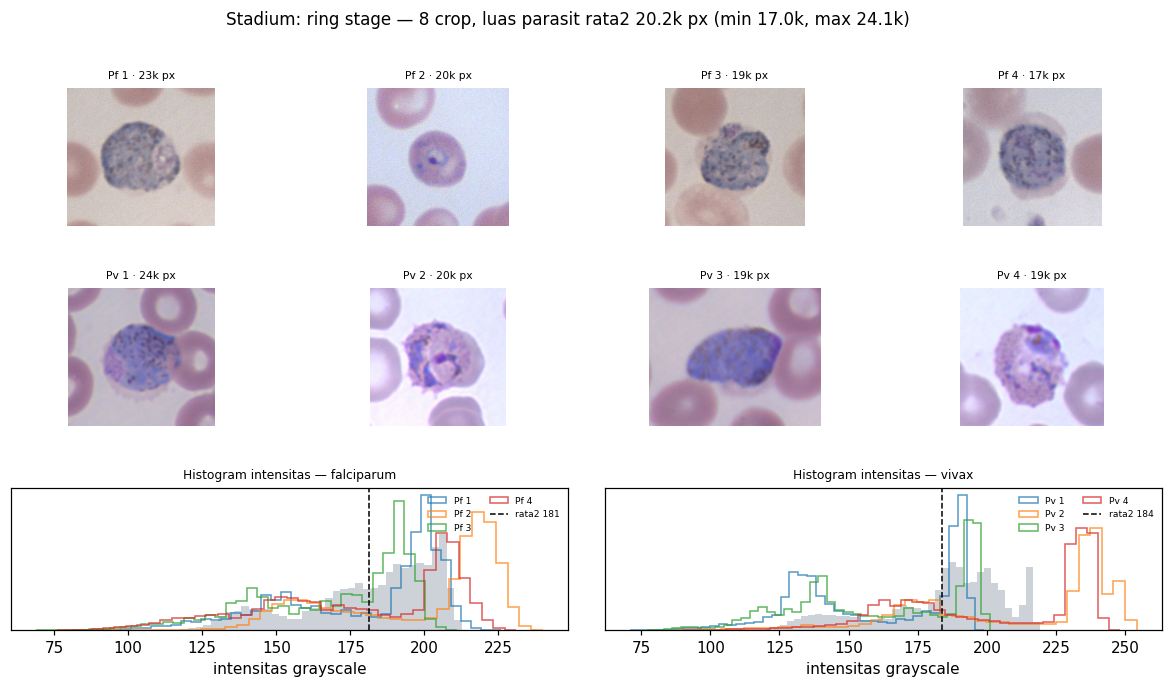

In [4]:
plot_stage('ring stage')

### 2.2 Stadium trophozoite

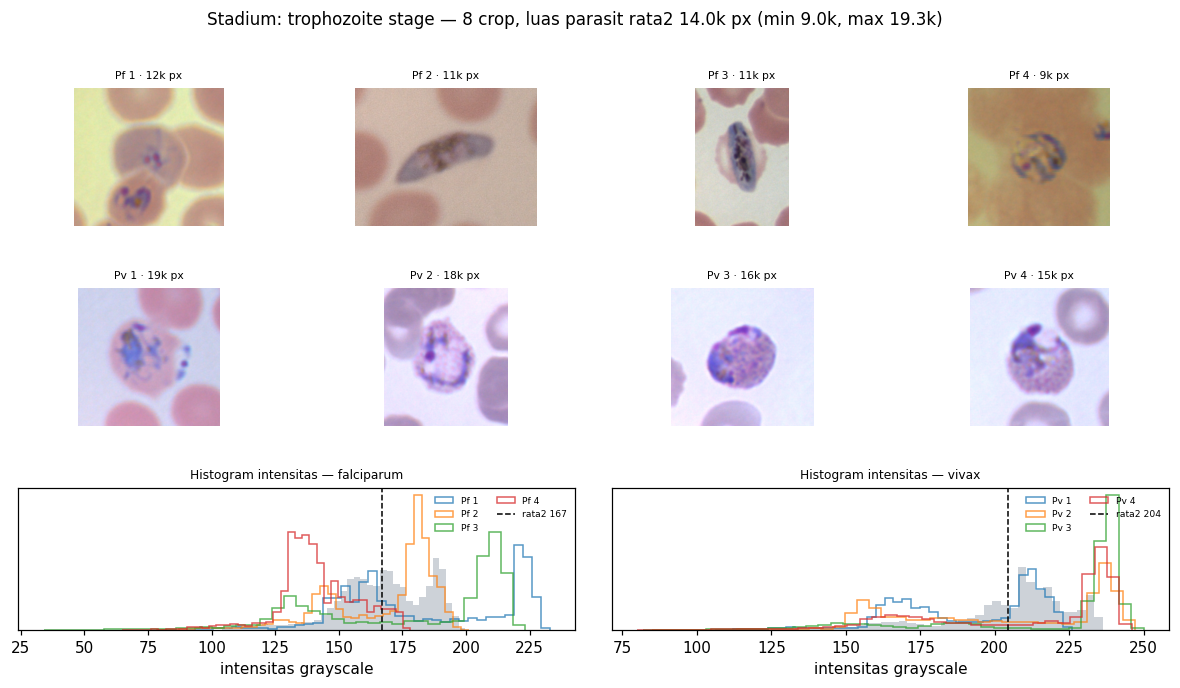

In [5]:
plot_stage('trophozoite stage')

### 2.3 Stadium schizont

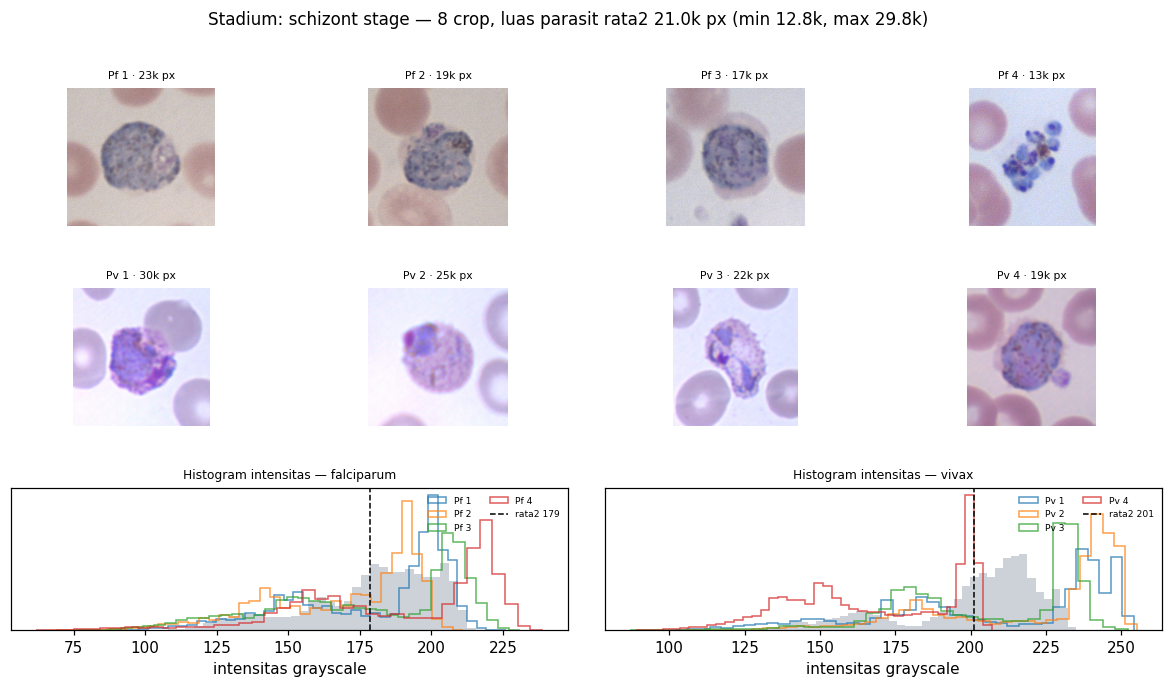

In [6]:
plot_stage('schizont stage')

### 2.4 Stadium gametocyte

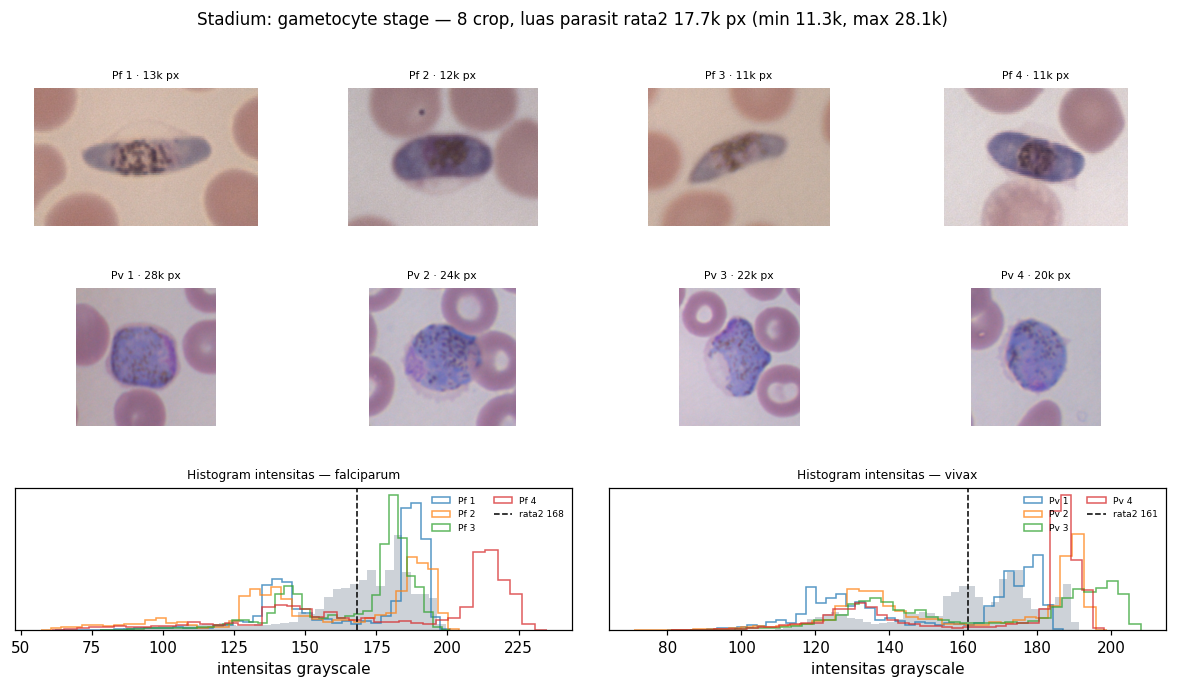

In [7]:
plot_stage('gametocyte stage')

### 2.5 Ringkasan angka per stadium

Tabel ini merekap stadium satu per satu sebelum digabung: jumlah crop, luas parasit, dan rata-rata intensitas grayscale tiap stadium/spesies.

In [8]:
rec = []
for st in STAGES:
    for sp in SPECIES:
        idxs = meta.index[(meta.stage == st) & (meta.species == sp)].tolist()
        g = gray_stack(idxs).mean(axis=0)
        rec.append({'stadium': st.replace(' stage', ''), 'spesies': sp, 'n': len(idxs),
                    'luas_parasit_kpx': meta.parasite_area_px[idxs].mean() / 1000,
                    'intensitas_rata2': g.mean(), 'intensitas_std': g.std(),
                    'piksel_gelap<80(%)': (g < 80).mean() * 100})
per_stage_table = pd.DataFrame(rec)
display(per_stage_table.round(2))
per_stage_table.to_csv(RESULTS_DIR / 'ringkasan_per_stadium.csv', index=False)

,stadium,spesies,n,luas_parasit_kpx,intensitas_rata2,intensitas_std,piksel_gelap<80(%)
0,ring,falciparum,4,19.75,181.27,22.29,0.00
1,ring,vivax,4,20.63,183.69,23.06,0.00
2,trophozoite,falciparum,4,11.03,166.88,18.64,0.00
3,trophozoite,vivax,4,17.01,204.35,22.17,0.00
4,schizont,falciparum,4,17.85,178.74,22.86,0.00
5,schizont,vivax,4,24.05,200.97,22.98,0.00
6,gametocyte,falciparum,4,11.96,168.06,22.32,0.02
7,gametocyte,vivax,4,23.44,161.37,19.53,0.00


## 3. Gabungan 32 citra

Baru setelah tiap stadium dibaca sendiri, semua crop digabung: grid lengkap 32 crop (baris = stadium, kolom = spesies), lalu distribusi luas parasit dan histogram gabungan.

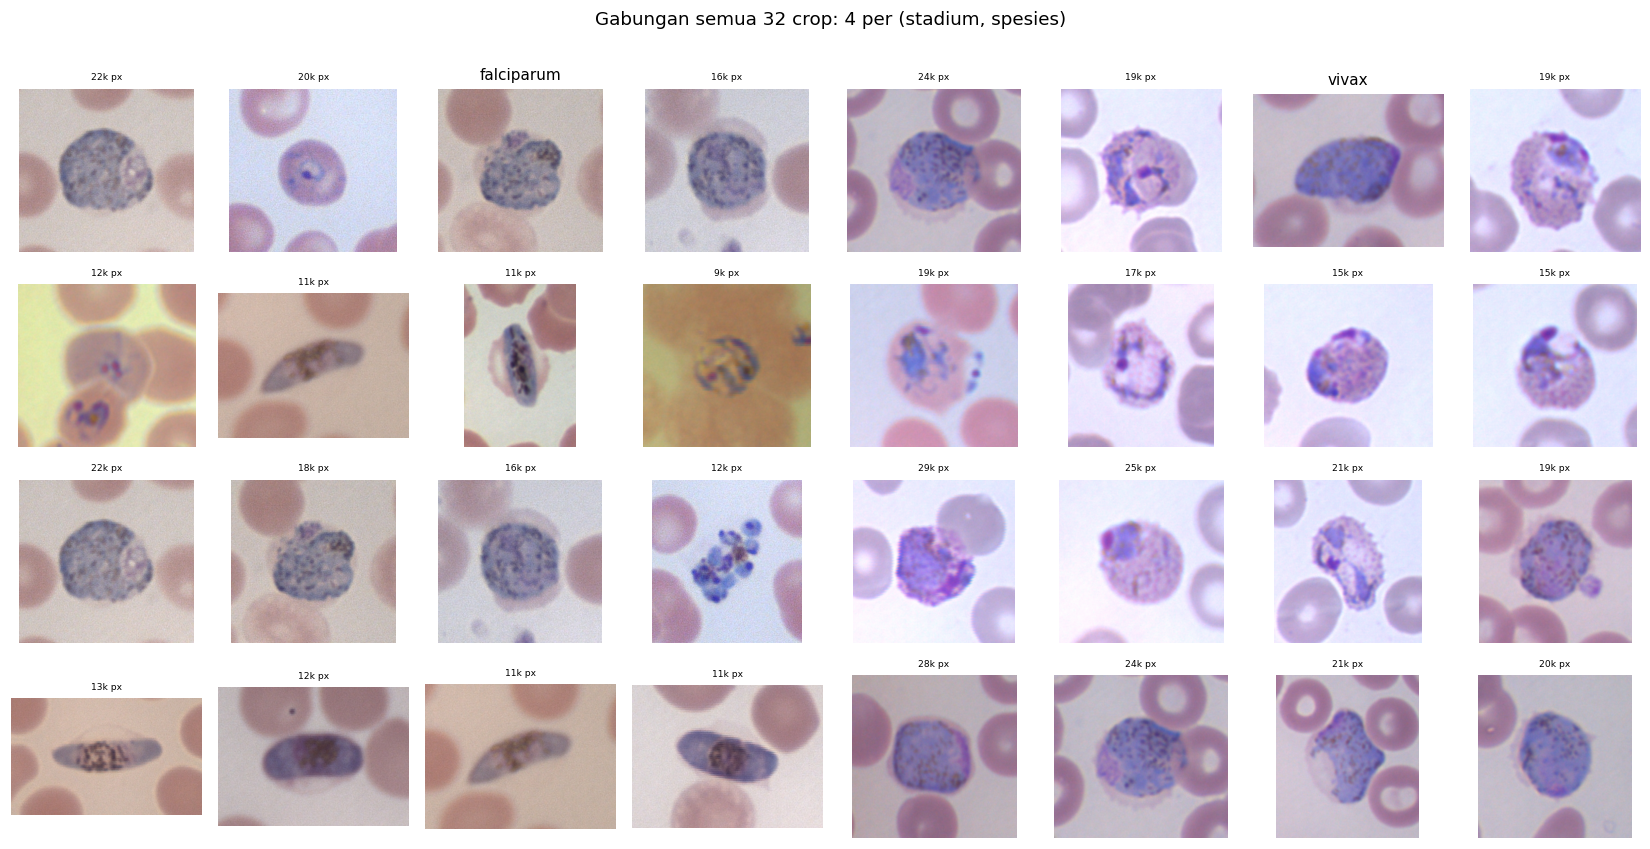

In [9]:
per_group = int(meta.groupby(['species', 'stage']).size().max())
fig, axes = plt.subplots(len(STAGES), 2 * per_group,
                         figsize=(1.9 * per_group, 1.9 * len(STAGES)) * np.array([2, 1]))
for i, st in enumerate(STAGES):
    for j, sp in enumerate(SPECIES):
        rows = meta[(meta.stage == st) & (meta.species == sp)].sort_values('filename')
        for k, (_, r) in enumerate(rows.iterrows()):
            idx = int(meta.index[meta.filename == r.filename][0])
            ax = axes[i, j * per_group + k]
            ax.imshow(crops[idx])
            ax.set_title(f'{r.parasite_area_px//1000}k px', fontsize=6)
for ax in axes.ravel():
    ax.axis('off')
for i, st in enumerate(STAGES):
    axes[i, 0].set_ylabel(st.replace(' stage', ''), fontsize=9)
for j, sp in enumerate(SPECIES):
    axes[0, j * per_group + per_group // 2].set_title(sp, fontsize=10)
plt.suptitle(f'Gabungan semua {len(meta)} crop: {per_group} per (stadium, spesies)', y=1.01)
plt.tight_layout(); plt.show()

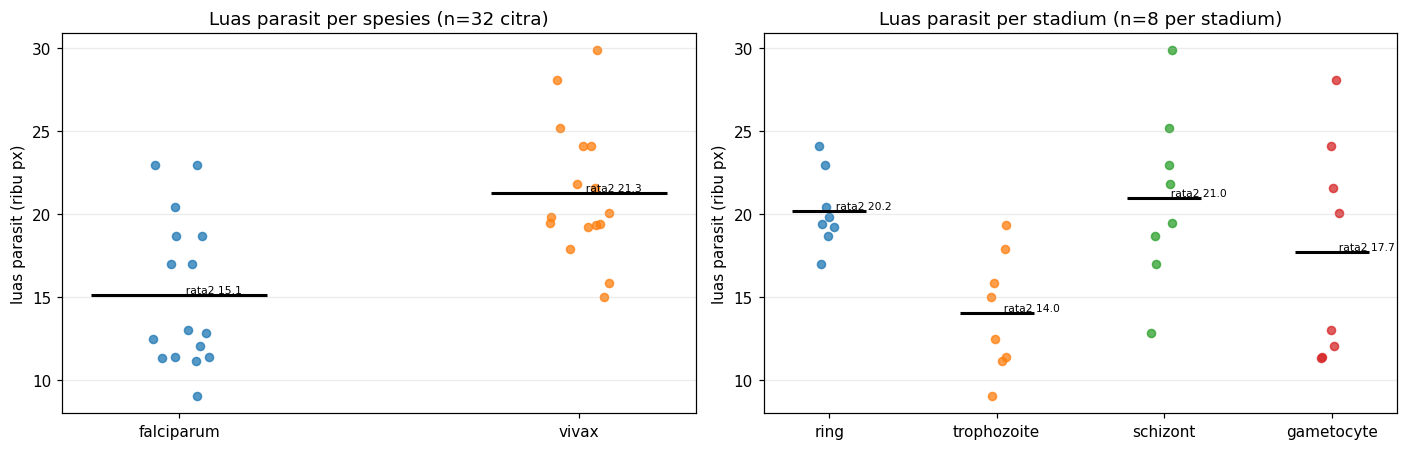

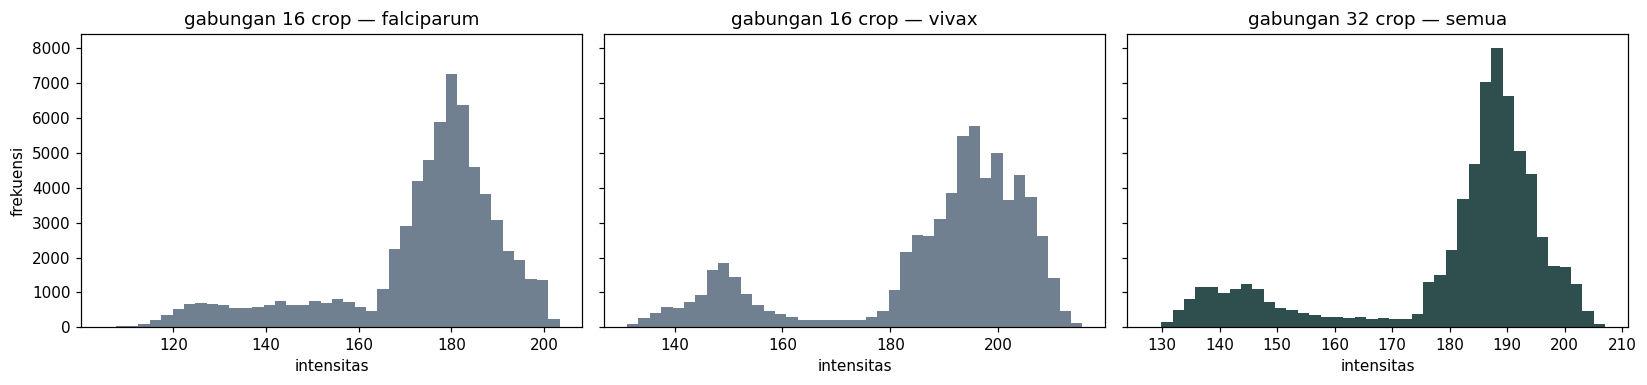

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rng = np.random.default_rng(42)
meta2 = meta.copy(); meta2['area_k'] = meta2.parasite_area_px / 1000
for ax, col in zip(axes, ['species', 'stage']):
    cats = list(meta2[col].unique())
    for i, c in enumerate(cats):
        vals = meta2.loc[meta2[col] == c, 'area_k'].to_numpy()
        ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, len(vals)), vals,
                   s=28, alpha=0.75, label=None)
        ax.hlines(vals.mean(), i - 0.22, i + 0.22, color='black', lw=2)
        ax.text(i, vals.mean(), f'  rata2 {vals.mean():.1f}', va='bottom', fontsize=7)
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels([str(c).replace(' stage', '') for c in cats])
    ax.set_ylabel('luas parasit (ribu px)')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_title(f'Luas parasit per spesies (n={len(meta2)} citra)')
axes[1].set_title('Luas parasit per stadium (n=8 per stadium)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, sp in zip(axes, SPECIES):
    idxs = meta.index[meta.species == sp].tolist()
    stack = gray_stack(idxs)
    ax.hist(stack.mean(axis=0), bins=40, color='slategray')
    ax.set_title(f'gabungan 16 crop — {sp}'); ax.set_xlabel('intensitas')
all_stack = gray_stack(meta.index.tolist())
axes[2].hist(all_stack.mean(axis=0), bins=40, color='darkslategray')
axes[2].set_title(f'gabungan {len(meta)} crop — semua')
axes[2].set_xlabel('intensitas')
axes[0].set_ylabel('frekuensi')
plt.tight_layout(); plt.show()

## 4. Preprocessing: tahapan dan efeknya

Tahapan yang diuji (satu per satu, kumulatif):

1. **Lab b** konversi warna, kanal b memisahkan parasit dari latar RBC
2. **+ koreksi background** closing besar mengestimasi latar, dikurangi dari citra
3. **+ median filter** meredam noise grain tanpa menggeser tepi
4. **+ CLAHE** penajaman kontras (kontrol)
5. **+ Reinhard** normalisasi warna pewarnaan ke referensi dataset (alternatif)

Setiap stadium (ring, trophozoite, schizont, gametocyte) ditampilkan satu contoh *P. falciparum*, masing-masing lengkap per tahap beserta histogramnya, supaya perbedaan efek antar stadium ikut terlihat.

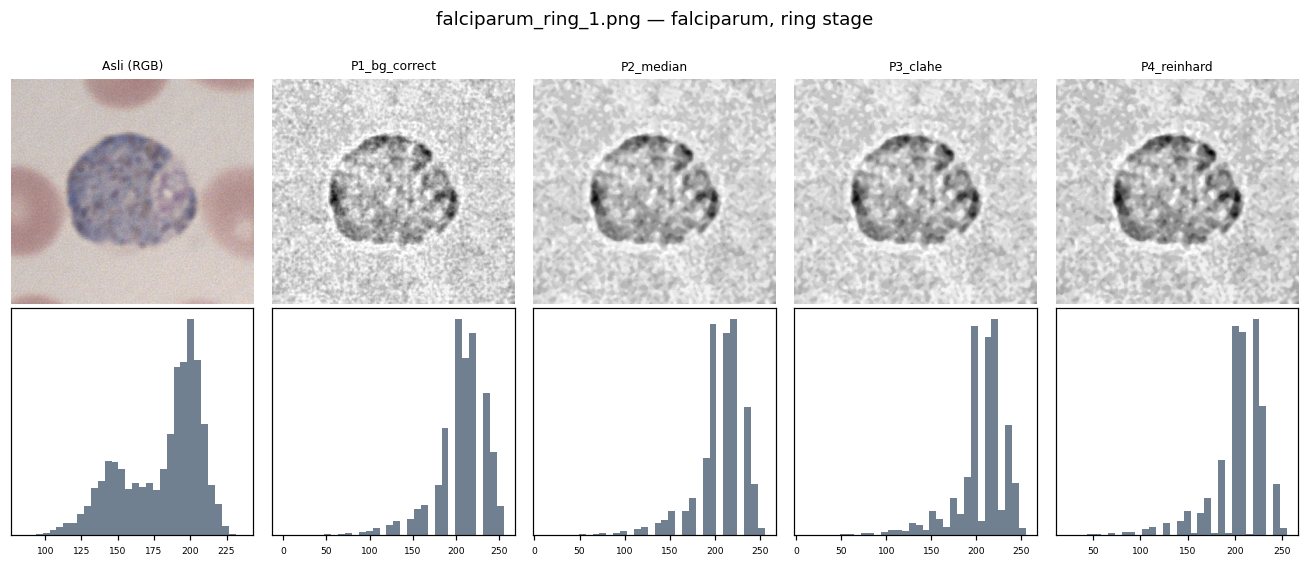

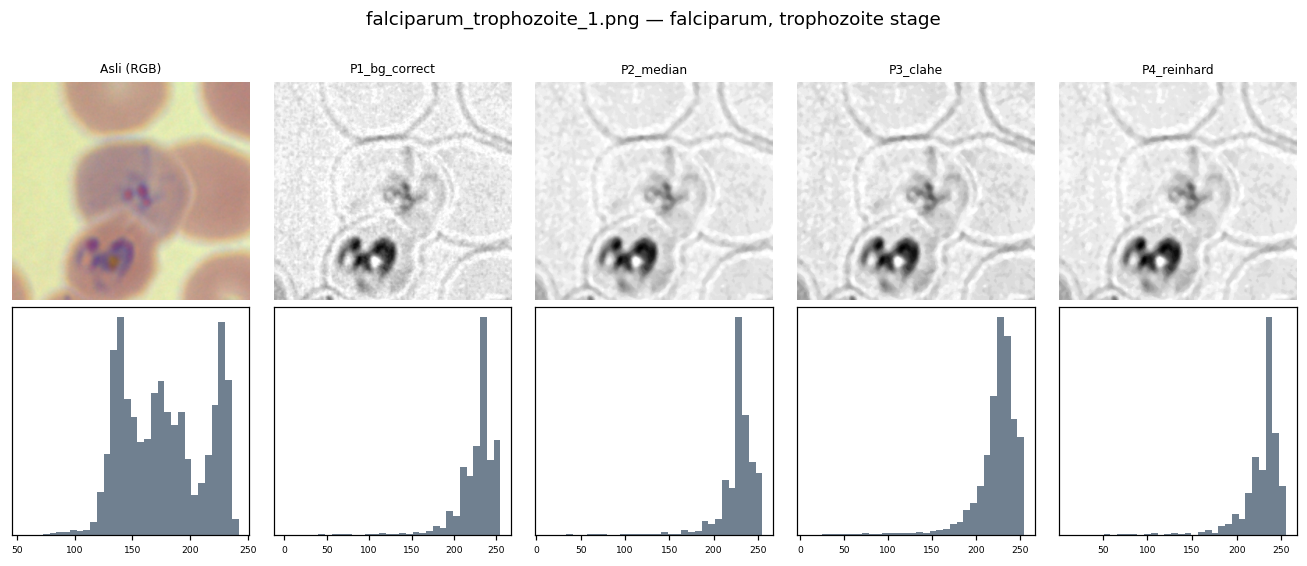

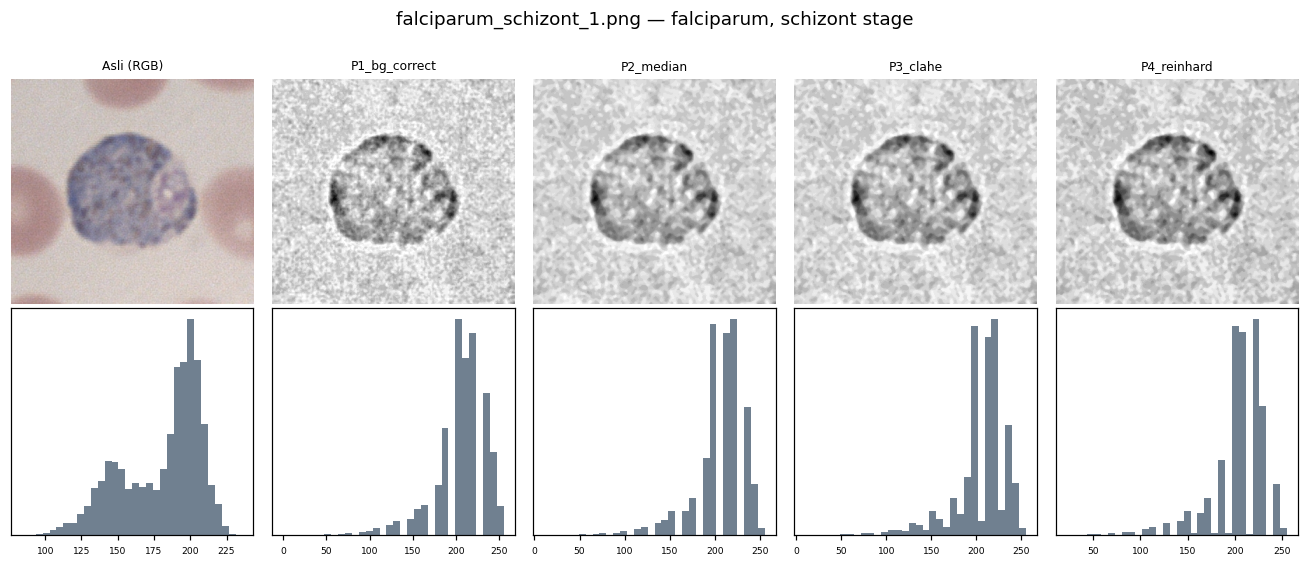

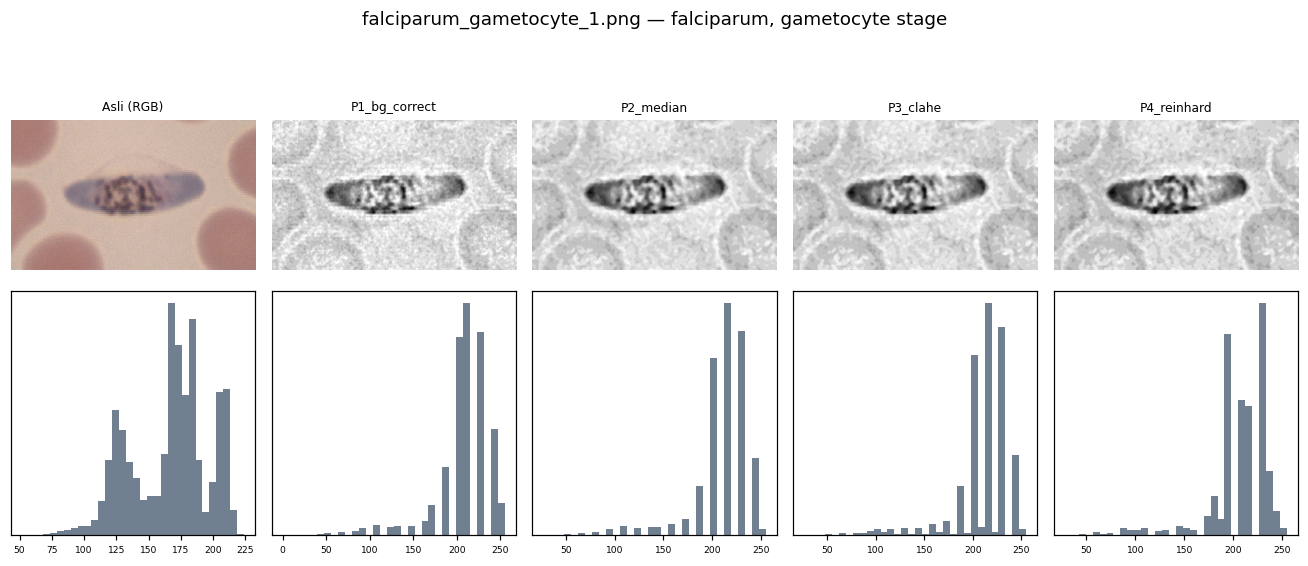

In [11]:
def lab_b(img): return cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[:, :, 2]
def bg_correct(chan, r=25):
    bg = cv2.morphologyEx(chan, cv2.MORPH_CLOSE, disk(r).astype(np.uint8))
    out = cv2.subtract(chan.astype(np.int16), bg.astype(np.int16))
    return cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
def median_f(chan, k=5): return cv2.medianBlur(chan, k)
def clahe_f(chan):
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(chan)

_labs = [cv2.cvtColor(img, cv2.COLOR_RGB2LAB) for img in crops]
REF_MEAN = np.concatenate([l.reshape(-1, 3) for l in _labs]).mean(axis=0)
REF_STD = np.concatenate([l.reshape(-1, 3) for l in _labs]).std(axis=0) + 1e-6
def reinhard(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float64)
    lab = (lab - lab.reshape(-1,3).mean(0)) / (lab.reshape(-1,3).std(0) + 1e-6) * REF_STD + REF_MEAN
    return cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)

PIPELINES = {
    'P0_Lab_b': lambda img: lab_b(img),
    'P1_bg_correct': lambda img: bg_correct(lab_b(img)),
    'P2_median': lambda img: median_f(bg_correct(lab_b(img))),
    'P3_clahe': lambda img: clahe_f(median_f(bg_correct(lab_b(img)))),
    'P4_reinhard': lambda img: median_f(bg_correct(lab_b(reinhard(img)))),
}

demo_stages = STAGES  # keempat stadium, termasuk trophozoite (stadium paling sulit)
demo_idx = [int(meta.index[(meta.stage == st) & (meta.species == 'falciparum')][0]) for st in demo_stages]
for idx in demo_idx:
    img = crops[idx]
    stages_v = [('Asli (RGB)', img)] + [(n, f(img)) for n, f in list(PIPELINES.items())[1:]]
    fig, axes = plt.subplots(2, len(stages_v), figsize=(2.4 * len(stages_v), 5))
    for j, (name, ch) in enumerate(stages_v):
        axes[0, j].imshow(ch, cmap='gray' if ch.ndim == 2 else None)
        axes[0, j].set_title(name, fontsize=8); axes[0, j].axis('off')
        axes[1, j].hist(ch.ravel(), bins=32, color='slategray'); axes[1, j].set_yticks([])
        axes[1, j].tick_params(labelsize=6)
    plt.suptitle(f'{meta.filename[idx]} — {meta.species[idx]}, {meta.stage[idx]}', y=1.02)
    plt.tight_layout(); plt.show()

## 5. Evaluasi segmentasi per stadium (dipisah)

Segmentasi tetap sama di semua stadium: Otsu multilevel 3 pada varian preprocessing, ambil kelas tergelap, buang objek < 12 px. Yang dipisah adalah **cara membaca hasilnya**: Dice dihitung dulu per stadium (8 citra per stadium), baru digabung di Bagian 6.

,n_citra,P0_Lab_b,P1_bg_correct,P2_median,P3_clahe,P4_reinhard
stadium,,,,,,
ring,8,0.7156,0.4478,0.4653,0.4987,0.4724
trophozoite,8,0.5591,0.3969,0.3917,0.4254,0.4183
schizont,8,0.7279,0.4418,0.4508,0.4983,0.4634
gametocyte,8,0.8091,0.4639,0.4655,0.5195,0.5128


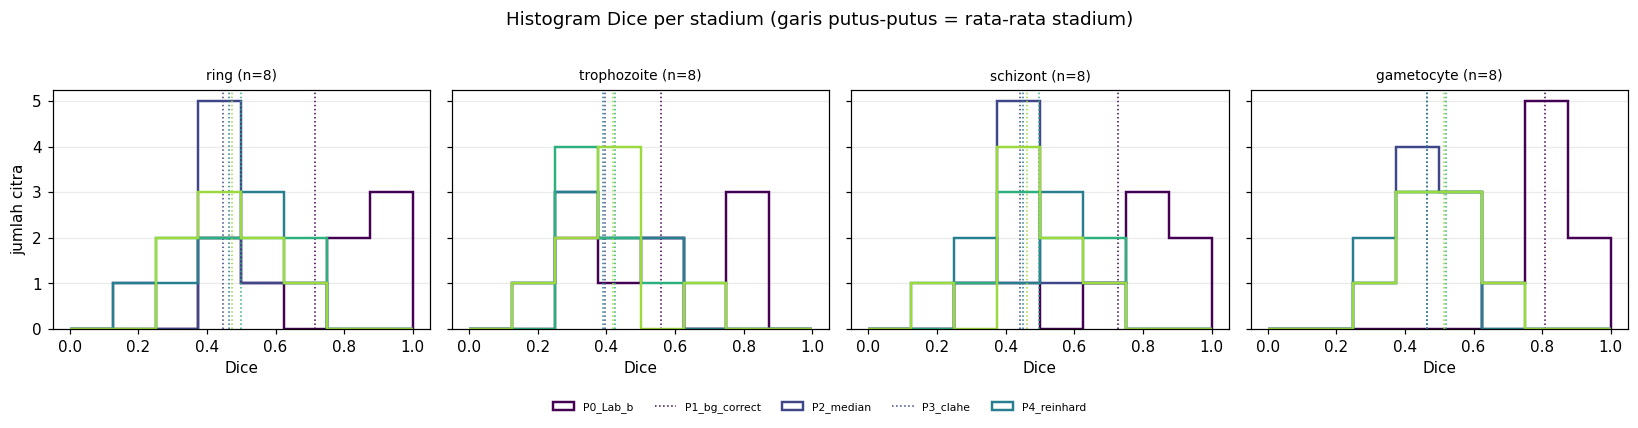

Tersimpan: /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/results/data_preprocessing/dice_per_stadium.csv


In [12]:
def seg_otsu3(chan):
    try:
        th = threshold_multiotsu(chan, classes=3)
        mask = chan < th[0]
    except Exception:
        mask = np.zeros(chan.shape, dtype=bool)
    return remove_small_objects(mask, max_size=MIN_AREA - 1, connectivity=2)

def dice_iou(pred, gt):
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum(); fn = np.logical_and(~pred, gt).sum()
    return 2*tp/(2*tp+fp+fn+1e-9), tp/(tp+fp+fn+1e-9)

per_img = {name: np.array([dice_iou(seg_otsu3(fn(img)), gt)[0] for img, gt in zip(crops, gts)])
           for name, fn in PIPELINES.items()}

stage_rows = []
for st in STAGES:
    m = (meta.stage == st).to_numpy()
    row = {'stadium': st.replace(' stage', ''), 'n_citra': int(m.sum())}
    for p in PIPELINES:
        row[p] = per_img[p][m].mean()
    stage_rows.append(row)
dice_per_stage = pd.DataFrame(stage_rows).set_index('stadium')
display(dice_per_stage.round(4))

fig, axes = plt.subplots(1, len(STAGES), figsize=(15, 3.4), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.85, len(PIPELINES)))
for ax, st in zip(axes, STAGES):
    m = (meta.stage == st).to_numpy()
    for c, p in zip(colors, PIPELINES):
        ax.hist(per_img[p][m], bins=8, range=(0, 1), histtype='step', lw=1.6,
                color=c, label=p if st == STAGES[0] else None)
        ax.axvline(per_img[p][m].mean(), color=c, ls=':', lw=1)
    ax.set_title(f'{st.replace(" stage", "")} (n={int(m.sum())})', fontsize=9)
    ax.set_xlabel('Dice'); ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('jumlah citra')
fig.legend(list(PIPELINES), fontsize=7, loc='lower center', ncol=len(PIPELINES),
           bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.suptitle('Histogram Dice per stadium (garis putus-putus = rata-rata stadium)', y=1.02)
plt.tight_layout(); plt.show()

dice_per_stage.round(4).to_csv(RESULTS_DIR / 'dice_per_stadium.csv')
print('Tersimpan:', RESULTS_DIR / 'dice_per_stadium.csv')

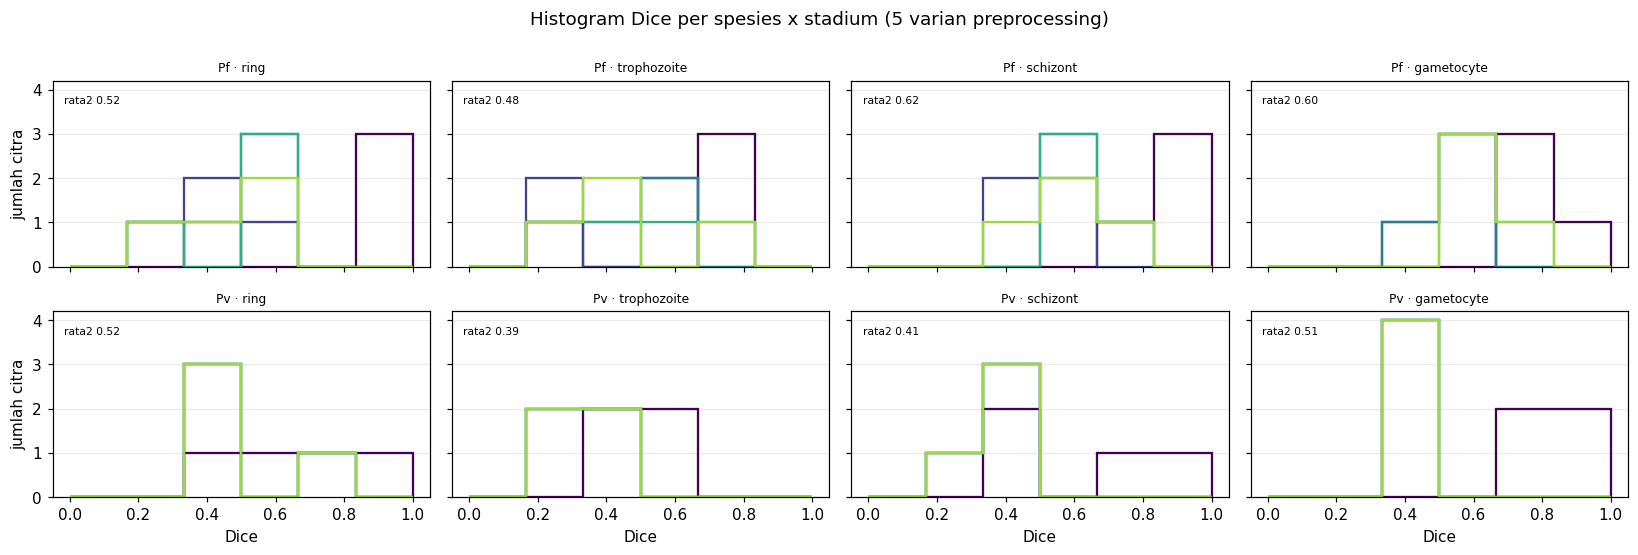

In [13]:
# Histogram Dice per stadium x spesies: 8 kelompok, tiap kelompok 4 citra x 5 varian
fig, axes = plt.subplots(2, len(STAGES), figsize=(15, 5), sharex=True, sharey=True)
for i, sp in enumerate(SPECIES):
    for j, st in enumerate(STAGES):
        ax = axes[i, j]
        m = ((meta.species == sp) & (meta.stage == st)).to_numpy()
        for c, p in zip(colors, PIPELINES):
            ax.hist(per_img[p][m], bins=6, range=(0, 1), histtype='step', lw=1.5, color=c)
        allv = np.concatenate([per_img[p][m] for p in PIPELINES])
        ax.set_title(f'{SHORT[sp]} · {st.replace(" stage", "")}', fontsize=8)
        ax.text(0.03, 0.92, f'rata2 {allv.mean():.2f}', transform=ax.transAxes, fontsize=7, va='top')
        ax.grid(axis='y', alpha=0.25)
for ax in axes[1]:
    ax.set_xlabel('Dice')
for ax in axes[:, 0]:
    ax.set_ylabel('jumlah citra')
plt.suptitle('Histogram Dice per spesies x stadium (5 varian preprocessing)', y=1.0)
plt.tight_layout(); plt.show()

## 6. Gabungan 32 citra: evaluasi keseluruhan

Setelah per stadium terbaca, semua 32 citra digabung seperti sebelumnya: tabel ringkasan, boxplot Dice, sebaran per kelompok, heatmap, dan histogram frekuensi.

,dice,iou
P0_Lab_b,0.7029,0.5737
P1_bg_correct,0.4376,0.2867
P2_median,0.4433,0.2923
P3_clahe,0.4855,0.3299
P4_reinhard,0.4667,0.3133


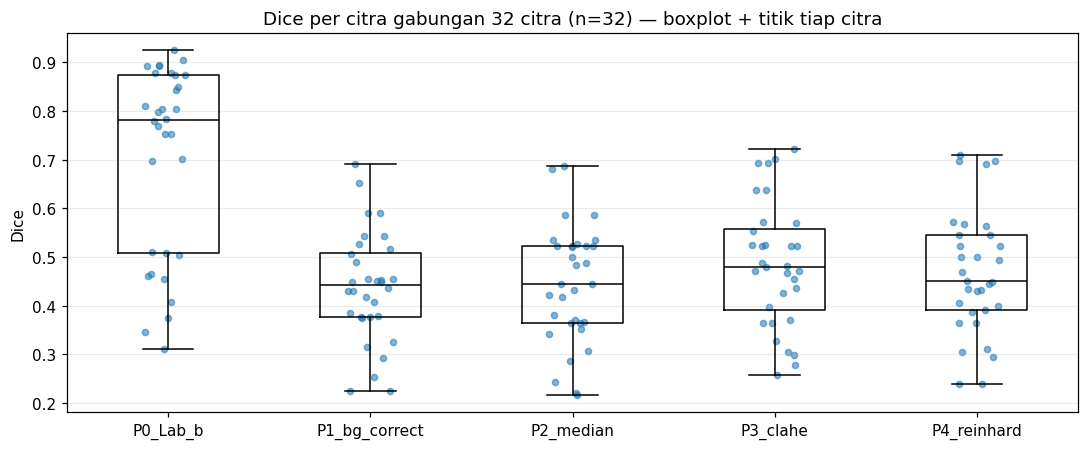

In [14]:
summary = pd.DataFrame({
    'dice': {p: per_img[p].mean() for p in PIPELINES},
    'iou': {p: np.mean([dice_iou(seg_otsu3(fn(img)), gt)[1] for img, gt in zip(crops, gts)])
            for p, fn in PIPELINES.items()},
}).round(4)
display(summary)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.boxplot([per_img[p] for p in PIPELINES], tick_labels=list(PIPELINES), widths=0.5,
           showfliers=False, medianprops={'color': 'black'})
for i, p in enumerate(PIPELINES, start=1):
    ax.scatter(np.full(len(per_img[p]), i) + rng.uniform(-0.12, 0.12, len(per_img[p])),
               per_img[p], s=16, alpha=0.55, color='tab:blue')
ax.set_ylabel('Dice'); ax.set_xlabel('')
ax.set_title(f'Dice per citra gabungan 32 citra (n={len(crops)}) — boxplot + titik tiap citra')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout(); plt.show()

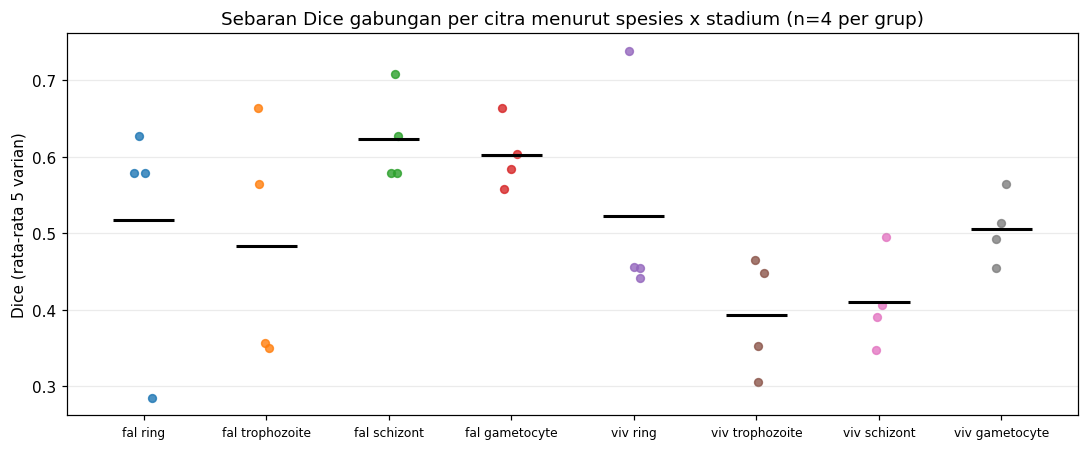

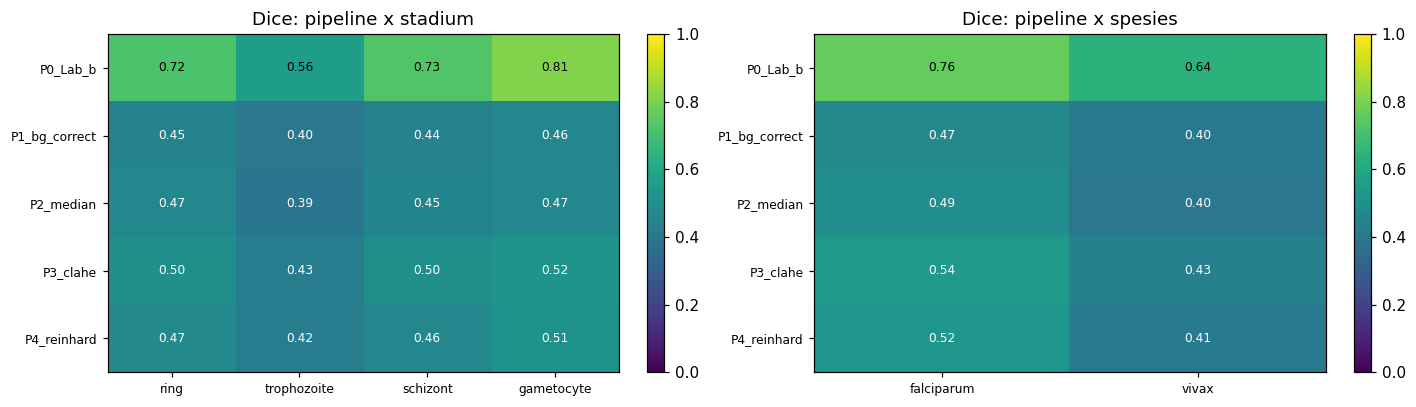

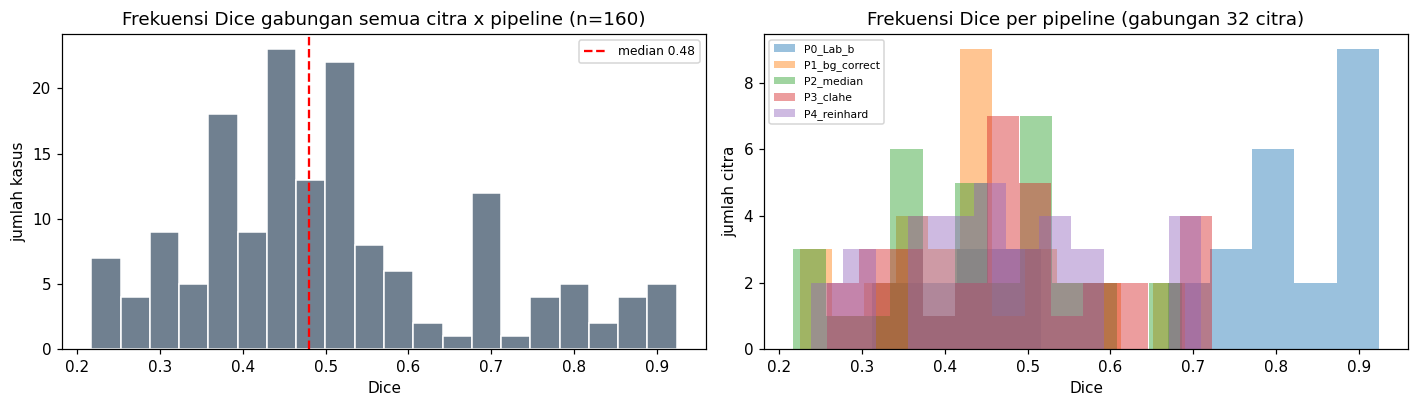

Tersimpan: /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/results/data_preprocessing/summary.csv
Per stadium: /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/results/data_preprocessing/dice_per_stadium.csv


In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (sp, st) in enumerate([(sp, st) for sp in SPECIES for st in STAGES], start=1):
    m = (meta.species == sp) & (meta.stage == st)
    vals = np.mean([per_img[p][m.to_numpy()] for p in PIPELINES], axis=0)
    ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, len(vals)), vals, s=26, alpha=0.8)
    ax.hlines(vals.mean(), i - 0.25, i + 0.25, color='black', lw=2)
ax.set_xticks(range(1, 9))
ax.set_xticklabels([f'{sp[:3]} {st.split()[0]}' for sp in SPECIES for st in STAGES], fontsize=8)
ax.set_ylabel('Dice (rata-rata 5 varian)')
ax.set_title('Sebaran Dice gabungan per citra menurut spesies x stadium (n=4 per grup)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout(); plt.show()

# Heatmap Dice: pipeline x stadium, dan pipeline x spesies
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, ttl in [(axes[0], 'stage', 'Dice: pipeline x stadium'),
                     (axes[1], 'species', 'Dice: pipeline x spesies')]:
    cats = [c for c in STAGES + SPECIES if c in set(meta[col])]
    mat = np.array([[per_img[p][(meta[col] == c).to_numpy()].mean() for c in cats]
                    for p in PIPELINES])
    im = ax.imshow(mat, cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels([c.replace(' stage', '') for c in cats], fontsize=8)
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(list(PIPELINES), fontsize=8)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center',
                    color='white' if mat[i, j] < 0.55 else 'black', fontsize=8)
    ax.set_title(ttl); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# Histogram frekuensi Dice gabungan: semua citra x pipeline + per pipeline
all_dice = np.concatenate([per_img[p] for p in PIPELINES])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(all_dice, bins=20, color='slategray', edgecolor='white')
axes[0].axvline(np.median(all_dice), color='red', ls='--', label=f'median {np.median(all_dice):.2f}')
axes[0].set_title(f'Frekuensi Dice gabungan semua citra x pipeline (n={len(all_dice)})')
axes[0].set_xlabel('Dice'); axes[0].set_ylabel('jumlah kasus'); axes[0].legend(fontsize=8)
for p in PIPELINES:
    axes[1].hist(per_img[p], bins=12, alpha=0.45, label=p)
axes[1].set_title('Frekuensi Dice per pipeline (gabungan 32 citra)'); axes[1].set_xlabel('Dice')
axes[1].set_ylabel('jumlah citra'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

summary.to_csv(RESULTS_DIR / 'summary.csv')
print('Tersimpan:', RESULTS_DIR / 'summary.csv')
print('Per stadium:', RESULTS_DIR / 'dice_per_stadium.csv')

## 7. Kesimpulan

- Dibaca **per stadium**, urutan varian sama seperti gabungan: **Lab b saja paling baik di keempat stadium**; semua tahap tambahan (koreksi background, median, CLAHE, Reinhard) menurunkan Dice.
- Dice Lab b tidak sama antar stadium: gametocyte 0.809, schizont 0.728, ring 0.716, trophozoite 0.559 (n=8 citra per stadium).
- Jarak Lab b ke varian terbaik berikutnya juga tidak seragam: gametocyte 0.345, schizont 0.286, ring 0.268, trophozoite 0.167. Jadi keunggulan Lab b paling mencolok di stadium besar, paling tipis di trophozoite.
- Hanya dari angka ini sebabnya belum bisa dipastikan; yang bisa dikatakan, stadium trophozoite paling sulit disegmentasi oleh semua varian sekaligus, bukan hanya oleh varian tertentu.
- Setelah digabung 32 citra, Dice Lab b 0.7029 dan IoU 0.5737. Angka gabungan ini menutupi variasi antar stadium, jadi pembacaan per stadium di Bagian 5 dipakai sebagai rujukan utama.
- Koreksi background lebih relevan untuk **citra penuh** (lihat notebook Progress 1), bukan untuk crop.

Angka lengkap: `results/data_preprocessing/summary.csv` (gabungan), `results/data_preprocessing/dice_per_stadium.csv` (per stadium), dan `results/data_preprocessing/ringkasan_per_stadium.csv` (statistik data per stadium).
